# Análise de Causa-Raiz em Defeitos de Placas-Mãe

**Pipeline de preparação e análise**

Este notebook orquestra o pipeline de preparação do corpus MES SMOM 2.29.02
(janeiro a março de 2026, semanas WK01 a WK10) e executa as análises de
causa-raiz sobre as bases derivadas.

Os números produzidos foram validados contra o Apêndice A da dissertação:
5.526 registros brutos, 5.498 após remoção de cabeçalhos, 5.235 defeitos
únicos e 5.078 eventos de teste distintos.

**Estrutura**

| Seção | Conteúdo |
|---|---|
| 0 | Configuração do ambiente |
| 1 | Validação da chave e integridade do corpus |
| 2 | Anonimização e pseudonimização |
| 3 | Limpeza e deduplicação |
| 4 | Engenharia de atributos |
| 5 | Carga e verificação das bases |
| 6 | Estatística descritiva |
| 7 | Associação com o estágio do defeito |
| 8 | Regras de associação |
| 9 | Detector de desvios de processo |
| 10 | Síntese |

## 0. Configuração do ambiente

O notebook carrega a configuração central do projeto (`config/experimento.yaml`)
para garantir que todos os parâmetros — seed, caminhos, limiares estatísticos —
venham de uma fonte única. Nenhum valor é fixado no código do notebook.

A função `rodar_script` executa os scripts do pipeline como subprocessos, o que
preserva a separação entre orquestração (notebook) e execução (scripts). Isso
garante que o notebook e a execução via linha de comando produzam exatamente o
mesmo resultado.

In [7]:
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns

RAIZ = Path.cwd()
CFG_PATH = RAIZ / "config" / "experimento.yaml"

if not CFG_PATH.exists():
    raise FileNotFoundError(f"Configuracao nao encontrada: {CFG_PATH}")

with open(CFG_PATH, encoding="utf-8") as f:
    CFG = yaml.safe_load(f)

WORKING = RAIZ / CFG["caminhos"]["working"]
OUTPUTS = RAIZ / CFG["caminhos"]["outputs"]

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

print(f"pandas  : {pd.__version__}")
print(f"numpy   : {np.__version__}")
print(f"seed    : {CFG['reprodutibilidade']['seed']}")
print(f"working : {WORKING}")


def rodar_script(nome):
    """Executa um script do pipeline e imprime a saida."""
    caminho = RAIZ / "scripts" / nome
    if not caminho.exists():
        print(f"[AVISO] Script nao encontrado: {caminho}")
        return None
    print("=" * 70)
    print(f"Executando: {nome}")
    print("=" * 70)
    resultado = subprocess.run(
        [sys.executable, str(caminho)],
        capture_output=True,
        text=True,
        cwd=RAIZ,
    )
    print(resultado.stdout)
    if resultado.returncode != 0:
        print("[ERRO]")
        print(resultado.stderr)
    return resultado.returncode

pandas  : 3.1.0
numpy   : 2.5.4
seed    : 42
working : /Users/nattachacarvalho/dissertacao-dataset/data/working


## 1. Validação da chave e integridade do corpus

A validação da chave precede a limpeza porque a definição da unidade de análise
condiciona todas as etapas seguintes. Se a chave estiver errada, a deduplicação
remove registros legítimos ou preserva duplicatas.

O script verifica três coisas:

1. **Integridade do arquivo bruto** — compara o hash SHA-256 do arquivo com o
   valor registrado na configuração. Se divergir, o arquivo foi alterado e os
   resultados não são comparáveis.
2. **Artefatos de exportação** — identifica linhas em que o valor da célula
   coincide com o nome da coluna, artefato do Excel que insere o cabeçalho a
   cada quebra de página.
3. **Estrutura da chave** — verifica quantas duplicatas existem na chave de
   evento (`Serial Number` + `Test Time`). Espera-se valor maior que zero,
   porque um evento de teste pode registrar vários defeitos.

**Resultado esperado:** 5.526 linhas brutas, 28 cabeçalhos removidos,
5.498 linhas válidas e 420 duplicatas na chave de evento.

In [8]:
rodar_script("validar_chave.py")

Executando: validar_chave.py
[OK] Hash SHA-256 confere: 772ea1fd6689da71...

Linhas brutas: 5526
[0] Cabecalhos repetidos removidos: 28
    Linhas validas: 5498

Test Time invalidos apos limpeza: 0
Seriais unicos: 4814
Linhas de placa retestada: 684

[1] Duplicatas na chave de evento: 420
    -> Esperado > 0: um evento pode ter varios defeitos.




0

## 2. Anonimização e pseudonimização

A pseudonimização substitui identificadores diretos por rótulos sintéticos
sequenciais, preservando a estrutura relacional sem expor os valores originais.
A diferença em relação à anonimização é que a pseudonimização é reversível
mediante os mapas de correspondência — por isso eles são armazenados em
`data/private/` e excluídos do controle de versão, conforme a LGPD
(Brasil, 2018).

Três colunas foram pseudonimizadas: `Serial Number` (placa_XXXX), `MO`
(mo_XXXX) e `Key Part No` (part_XXXX). Quatro colunas previstas no desenho
original não existem na extração — `OP`, `Repair Order`, `Shipment` e
`Customer Part No` — e o script emite aviso e prossegue.

**Resultado esperado:** 5.526 linhas × 63 colunas, com três mapas gerados em
`data/private/`.

In [9]:
rodar_script("00_anonimizacao.py")

Executando: 00_anonimizacao.py
Entrada: 5526 linhas x 63 colunas
[OK] Serial Number -> placa_XXXX (4815 valores)
[OK] MO -> mo_XXXX (183 valores)
[OK] Key Part No -> part_XXXX (44 valores)
[AVISO] Coluna ausente: OP
[AVISO] Coluna ausente: Repair Order
[AVISO] Coluna ausente: Shipment
[AVISO] Coluna ausente: Customer Part No

Salvo: /Users/nattachacarvalho/dissertacao-dataset/data/working/base_anonimizada.xlsx
Saida: 5526 linhas x 63 colunas



0

## 3. Limpeza e deduplicação

A limpeza executa cinco operações sequenciais:

1. **Remoção de 41 colunas não-coleta** — colunas previstas no esquema do MES
   que não são utilizadas no processo produtivo, com aproximadamente 99,5% de
   valores ausentes.
2. **Remoção de 28 cabeçalhos repetidos** — artefatos de exportação.
3. **Criação de `evento_id`** — agrupa os registros do mesmo evento de teste
   (`Serial Number` + `Test Time`).
4. **Criação de `defeito_id`** — identifica cada defeito individualmente
   (`Serial Number` + `Test Time` + `Component` + `Location Desc`).
5. **Deduplicação** — remove registros com `defeito_id` repetido.
6. **Criação de `houve_reparo`** — derivada do preenchimento de `Repair Time`.

A chave de defeito usa `Component` e `Location Desc` porque essas duas colunas
identificam a **posição física** do defeito na placa. `Reason Desc` é atributo
descritivo do defeito, não identificador — dois defeitos na mesma posição com
a mesma causa são o mesmo defeito.

**Nota metodológica.** Dos quatro registros com `State Flag` ausente, dois eram
duplicata exata e foram reduzidos a um. Restaram três, preenchidos com valor 1
na etapa de engenharia de atributos.

**Resultado esperado:** 5.235 linhas × 25 colunas, 5.078 eventos únicos,
263 duplicatas removidas.

In [10]:
rodar_script("01_limpeza.py")

Executando: 01_limpeza.py
Entrada: 5526 linhas x 63 colunas
[1] Dicionario lido: 41 colunas nao-coleta
[1] Removidas 41 colunas sem coleta no MES
[2] Removidas 28 linhas de cabecalho repetido
[3] evento_id criado: 5078 eventos unicos
[4] defeito_id criado: 5235 defeitos unicos
[5] Deduplicacao: 5498 -> 5235 linhas (263 removidas)
[6] houve_reparo: 5023 com reparo (96.0%)

[7] Validacao final
    Linhas: 5235
    Colunas: 25
    Nulos em State Flag: 3
    Duplicatas de defeito_id: 0

Salvo: /Users/nattachacarvalho/dissertacao-dataset/data/working/base_limpa.xlsx
Saida: 5235 linhas x 25 colunas



0

## 4. Engenharia de atributos

O script `02_features.py` produz duas bases com granularidades distintas:

- **`base_defeito`** (5.235 × 103) — unidade de análise de causa-raiz. Cada
  linha é um defeito.
- **`base_evento`** (5.078 × 105) — unidade de análise de evento. Cada linha é
  um evento de teste, com contagens agregadas de defeitos, componentes e
  estágios.

As transformações aplicadas são:

- **`estagio_defeito`** — derivada de `State Flag`: 1 = primeira falha,
  3 = refalha. O valor 2 (reteste) não ocorre na base.
- **`component_tipo`** e **`loc_tipo`** — extraídos do prefixo da designação
  (`C` → capacitor, `R` → resistor, `U` → CI, `J` → conector). A ordem do mapa
  de prefixos importa: prefixos específicos (`TP`, `TSL`, `TQ`, `TR`) vêm antes
  dos genéricos (`T`) para não serem capturados por engano.
- **Controle de cardinalidade** — categorias com menos de 10 ocorrências são
  agrupadas em `OUTROS`; o total é limitado a 15 categorias por coluna.
- **Features temporais** — hora, dia da semana e semana ISO do teste.
- **One-hot encoding** — 8 colunas categóricas geram 93 dummies.

**Resultado esperado:** `base_defeito` 5.235 × 103, `base_evento` 5.078 × 105,
zero nulos nas bases finais.

In [11]:
rodar_script("02_features.py")

Executando: 02_features.py
Entrada: 5235 linhas x 25 colunas

[1] State Flag como feature descritiva de estagio
    Valores invalidos (NaN): 3
    ATRIBUINDO State Flag = 1 aos 3 registros invalidos
    Justificativa: defeitos completos, evento unico, padrao DEBUG/FT0/TS
    Distribuicao:
      1: 4889 (93.4%)
      3: 346 (6.6%)
    estagio_defeito: 1=primeira falha, 3=refalha (2=reteste nao ocorre)

[2] Location Desc -> tipo de componente
    loc_n_posicoes: media 1.01, max 4
    loc_tipo: 17 tipos
    Distribuicao de loc_tipo:
      CONECTOR       :  1657 (31.65%)
      CAPACITOR      :   937 (17.90%)
      CI             :   846 (16.16%)
      RESISTOR       :   584 (11.16%)
      DIODO          :   323 ( 6.17%)
      INDUTOR        :   164 ( 3.13%)
      TRANSISTOR     :   137 ( 2.62%)
      PLACA          :   119 ( 2.27%)
      PONTO_TESTE    :    86 ( 1.64%)
      FUSIVEL        :    73 ( 1.39%)
      CHAVE          :    71 ( 1.36%)
      MECANICO       :    67 ( 1.28%)
      FU

0

## 5. Carga e verificação das bases

As seções 5 a 10 são análise e podem rodar independentemente, desde que as
bases já existam em `data/working/`. Se você já executou o pipeline pela linha
de comando, pode começar daqui.

In [12]:
base_defeito = pd.read_excel(WORKING / "base_defeito.xlsx")
base_evento = pd.read_excel(WORKING / "base_evento.xlsx")
base_limpa = pd.read_excel(WORKING / "base_limpa.xlsx")

print(f"base_defeito : {base_defeito.shape[0]:>5} linhas x {base_defeito.shape[1]:>3} colunas")
print(f"base_evento  : {base_evento.shape[0]:>5} linhas x {base_evento.shape[1]:>3} colunas")
print(f"base_limpa   : {base_limpa.shape[0]:>5} linhas x {base_limpa.shape[1]:>3} colunas")

assert base_defeito.shape == (5235, 103), "Dimensoes inesperadas em base_defeito"
assert base_evento.shape == (5078, 105), "Dimensoes inesperadas em base_evento"
print("\nDimensoes conferem com o apendice A.")

base_defeito :  5235 linhas x 103 colunas
base_evento  :  5078 linhas x 105 colunas
base_limpa   :  5235 linhas x  25 colunas

Dimensoes conferem com o apendice A.


## 6. Estatística descritiva

A análise descritiva caracteriza a distribuição dos defeitos e identifica
desequilíbrios que condicionam a interpretação.

O desequilíbrio mais importante é o de `estagio_defeito`: 93,4% dos defeitos são
primeira falha e apenas 6,6% são refalha. Isso significa que qualquer análise
que compare os dois grupos trabalha com amostras de tamanhos muito diferentes —
o que exige cuidado com testes estatísticos e com a interpretação de taxas.

Distribuicao de estagio_defeito:
 estagio  defeitos  percentual
     1.0      4886       93.33
     3.0       346        6.61


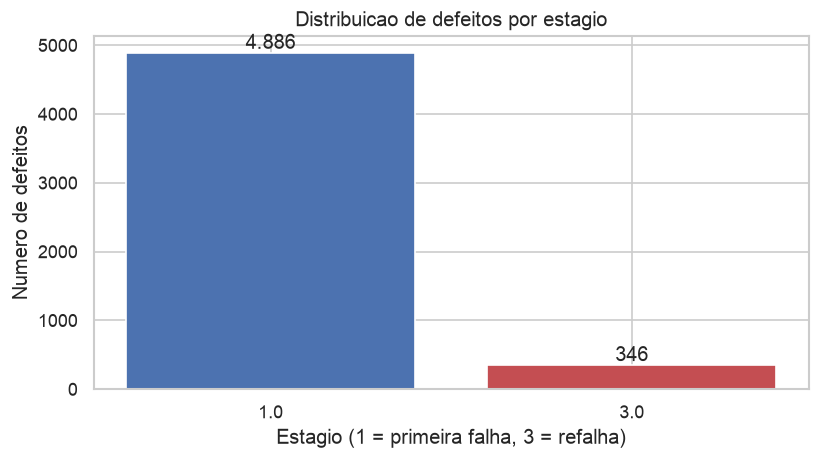

In [13]:
cont = base_limpa["State Flag"].value_counts().sort_index()
tabela = pd.DataFrame({
    "estagio": cont.index,
    "defeitos": cont.values,
    "percentual": (cont.values / len(base_limpa) * 100).round(2),
})
print("Distribuicao de estagio_defeito:")
print(tabela.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tabela["estagio"].astype(str), tabela["defeitos"], color=["#4C72B0", "#C44E52"])
ax.set_title("Distribuicao de defeitos por estagio")
ax.set_xlabel("Estagio (1 = primeira falha, 3 = refalha)")
ax.set_ylabel("Numero de defeitos")
for i, v in enumerate(tabela["defeitos"]):
    ax.text(i, v, f"{v:,}".replace(",", "."), ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [14]:
cont = base_limpa["houve_reparo"].value_counts().sort_index()
print("Distribuicao de houve_reparo:")
for v, q in cont.items():
    print(f"    {v}: {q} ({q/len(base_limpa)*100:.1f}%)")

n_def = base_limpa.groupby("evento_id").size().value_counts().sort_index()
print("\nDefeitos por evento:")
for v, q in n_def.items():
    print(f"    {v} defeito(s): {q} eventos ({q/base_limpa['evento_id'].nunique()*100:.1f}%)")

Distribuicao de houve_reparo:
    0: 212 (4.0%)
    1: 5023 (96.0%)

Defeitos por evento:
    1 defeito(s): 4944 eventos (97.4%)
    2 defeito(s): 111 eventos (2.2%)
    3 defeito(s): 23 eventos (0.5%)


       tipo  defeitos  percentual
   CONECTOR      1754       33.51
  CAPACITOR       936       17.88
         CI       859       16.41
   RESISTOR       583       11.14
      DIODO       235        4.49
    INDUTOR       162        3.09
 TRANSISTOR       135        2.58
      PLACA       117        2.23
PONTO_TESTE        84        1.60
    FUSIVEL        73        1.39


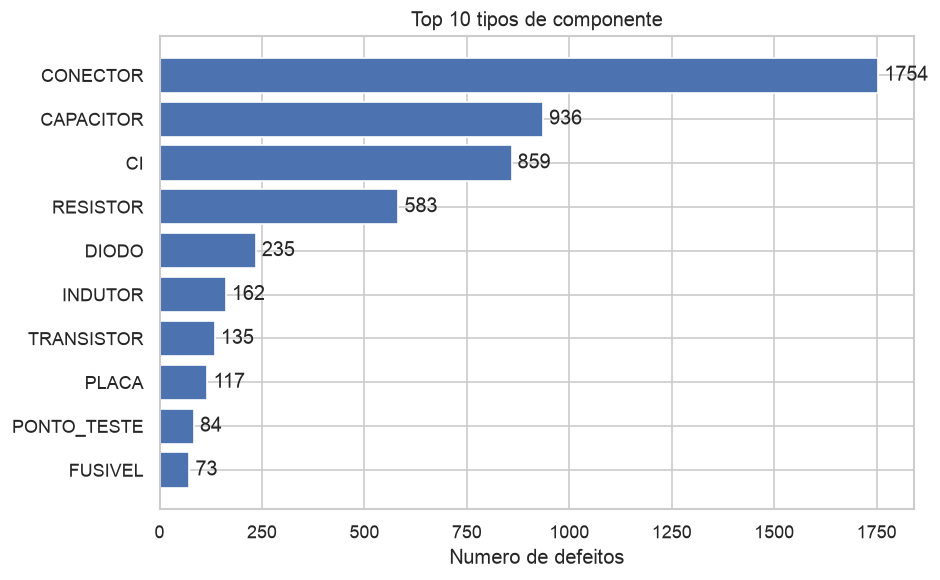

In [15]:
MAPA_PREFIXOS = [
    ("BRACKET", "MECANICO"), ("BRACKT", "MECANICO"), ("MYLAR", "MECANICO"),
    ("GASKET", "MECANICO"), ("ETIQUETA", "MECANICO"), ("NUT", "MECANICO"),
    ("HS", "MECANICO"), ("BATT", "MECANICO"), ("BAT", "MECANICO"),
    ("BT", "MECANICO"), ("H", "FURO_MONTAGEM"),
    ("PCB", "PLACA"), ("MB", "PLACA"), ("SN", "SERIAL"),
    ("HDMI", "CONECTOR"), ("OPTION", "CONECTOR"), ("WLAN", "CONECTOR"),
    ("WL", "CONECTOR"), ("KMCOM", "CONECTOR"), ("KBBL", "CONECTOR"),
    ("AUD", "CONECTOR"), ("J", "CONECTOR"), ("P", "CONECTOR"),
    ("BIOS", "CI"), ("EU", "CI"), ("AD", "CI"), ("U", "CI"), ("IC", "CI"),
    ("EC", "CAPACITOR"), ("C", "CAPACITOR"),
    ("EL", "INDUTOR"), ("L", "INDUTOR"),
    ("ED", "DIODO"), ("D", "DIODO"), ("LED", "LED"),
    ("R", "RESISTOR"), ("TR", "RESISTOR"),
    ("Q", "TRANSISTOR"), ("TQ", "TRANSISTOR"),
    ("Y", "CRISTAL"), ("X", "CRISTAL"),
    ("F", "FUSIVEL"),
    ("TP", "PONTO_TESTE"), ("TSL", "PONTO_TESTE"),
    ("SW", "CHAVE"), ("S", "CHAVE"),
    ("MH", "FURO_MONTAGEM"),
    ("ER", "OUTROS_TIPO"), ("AR", "OUTROS_TIPO"), ("EQ", "OUTROS_TIPO"),
    ("HE", "OUTROS_TIPO"), ("NTF", "OUTROS_TIPO"),
    ("T", "OUTROS_TIPO"),
]


def tipo_componente(s):
    s = str(s).strip().upper()
    if s in ("", "NAN", "NONE"):
        return "SEM_LOCAL"
    for prefixo, tipo in MAPA_PREFIXOS:
        if s.startswith(prefixo):
            return tipo
    return "OUTROS_TIPO"


base_limpa["component_tipo"] = (
    base_limpa["Component"].fillna("").astype(str).str.strip().apply(tipo_componente)
)
base_limpa["loc_tipo"] = (
    base_limpa["Location Desc"].fillna("").astype(str).str.strip().apply(tipo_componente)
)

cont = base_limpa["component_tipo"].value_counts().head(10)
tabela = pd.DataFrame({
    "tipo": cont.index,
    "defeitos": cont.values,
    "percentual": (cont.values / len(base_limpa) * 100).round(2),
})
print(tabela.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(tabela["tipo"][::-1], tabela["defeitos"][::-1], color="#4C72B0")
ax.set_title("Top 10 tipos de componente")
ax.set_xlabel("Numero de defeitos")
for i, v in enumerate(tabela["defeitos"][::-1]):
    ax.text(v, i, f" {v}", va="center")
plt.tight_layout()
plt.show()

              causa  defeitos  percentual
    COMPONENT SHIFT      1060       20.25
        NON-WETTING       675       12.89
   COMPONENT DAMAGE       459        8.77
  COMPONENT MISSING       320        6.11
     COMPONENT FAIL       304        5.81
   FOREIGN MATERIAL       237        4.53
       SOLDER SHORT       189        3.61
INSUFFICIENT SOLDER       172        3.29
     MATERIAL ISSUE       160        3.06
          TOMBSTONE       145        2.77


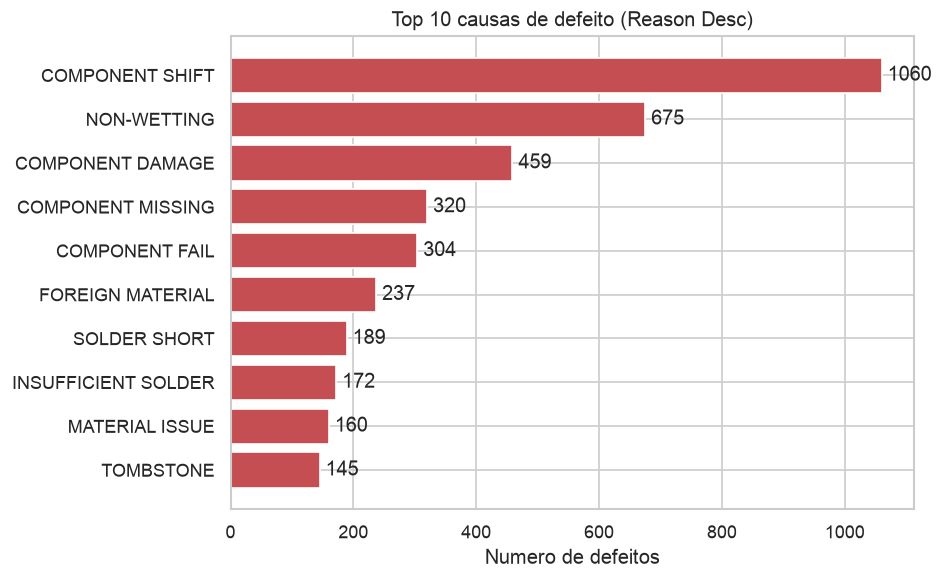

In [16]:
cont = base_limpa["Reason Desc"].value_counts().head(10)
tabela = pd.DataFrame({
    "causa": cont.index,
    "defeitos": cont.values,
    "percentual": (cont.values / len(base_limpa) * 100).round(2),
})
print(tabela.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(tabela["causa"][::-1], tabela["defeitos"][::-1], color="#C44E52")
ax.set_title("Top 10 causas de defeito (Reason Desc)")
ax.set_xlabel("Numero de defeitos")
for i, v in enumerate(tabela["defeitos"][::-1]):
    ax.text(v, i, f" {v}", va="center")
plt.tight_layout()
plt.show()

## 7. Associação com o estágio do defeito

O teste qui-quadrado verifica se duas variáveis categóricas são independentes.
O p-valor indica a probabilidade de observar a associação por acaso — mas ele
cresce com o tamanho da amostra, então com 5.235 registros quase toda associação
aparece como significativa.

Por isso o teste é acompanhado do **V de Cramér**, que mede o tamanho do efeito
em escala de 0 a 1:

| V de Cramér | Interpretação |
|---|---|
| < 0,10 | desprezível |
| 0,10 – 0,30 | fraco |
| 0,30 – 0,50 | moderado |
| > 0,50 | forte |

A análise busca identificar quais variáveis estão associadas ao estágio do
defeito — primeira falha versus refalha. Uma associação forte com `Test Station`
sugere que o problema está concentrado em uma estação; uma associação com
`component_tipo` sugere que o problema é de projeto ou de fornecedor.

**Associação não é causalidade.** O V de Cramér indica onde investigar, não a
causa do defeito.

      variavel   chi2  p_valor  gl  v_cramer    n significativo   magnitude
   Reason Desc 602.52 1.41e-90  60    0.3393 5235           sim    moderado
  Test Station 534.25 1.01e-99  21    0.3195 5235           sim    moderado
    Test Group 259.12 2.00e-51   8    0.2225 5235           sim       fraco
     Test Line 236.49 1.26e-46   8    0.2125 5235           sim       fraco
      loc_tipo  59.62 6.07e-07  16    0.1067 5235           sim       fraco
component_tipo  54.51 2.15e-06  15    0.1020 5235           sim       fraco
    Model Name  46.12 1.66e-04  17    0.0939 5235           sim desprezivel


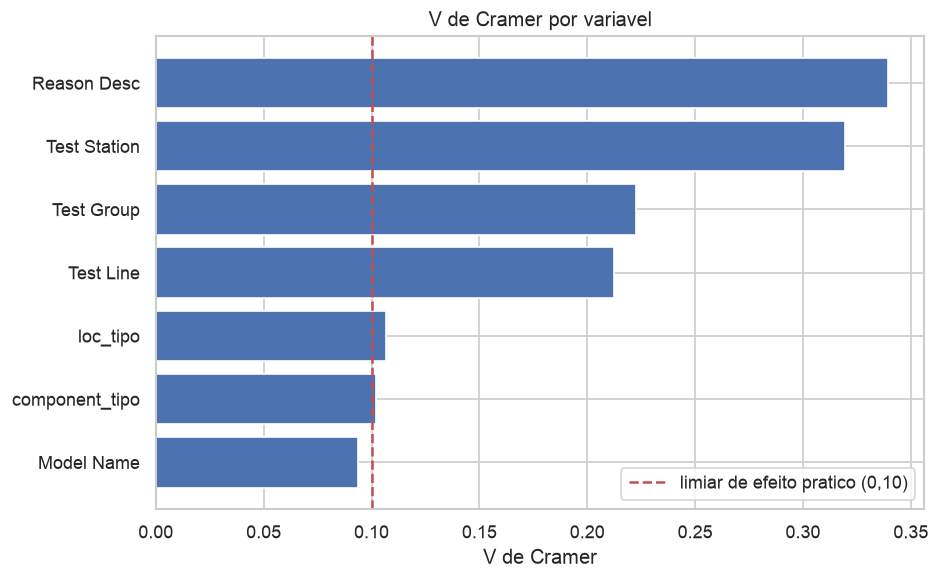

In [17]:
from scipy.stats import chi2_contingency


def v_cramer(tabela):
    """Calcula qui-quadrado e V de Cramer de uma tabela de contingencia."""
    chi2, p, gl, _ = chi2_contingency(tabela)
    n = tabela.values.sum()
    k = min(tabela.shape) - 1
    v = np.sqrt(chi2 / (n * k)) if k > 0 and n > 0 else 0.0
    return {"chi2": chi2, "p": p, "gl": gl, "v": v, "n": n}


def magnitude(v):
    if v < 0.10:
        return "desprezivel"
    if v < 0.30:
        return "fraco"
    if v < 0.50:
        return "moderado"
    return "forte"


ALPHA = CFG["analise"]["alpha"]
base_limpa["estagio_defeito"] = (
    pd.to_numeric(base_limpa["State Flag"], errors="coerce").fillna(1).astype(int)
)

VARIAVEIS = [
    "Model Name", "Test Line", "Test Group", "Test Station",
    "Reason Desc", "Duty Type", "component_tipo", "loc_tipo",
]

resultados = []
for var in VARIAVEIS:
    if var not in base_limpa.columns:
        continue
    tabela = pd.crosstab(base_limpa[var], base_limpa["estagio_defeito"])
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        continue
    r = v_cramer(tabela)
    resultados.append({
        "variavel": var,
        "chi2": round(r["chi2"], 2),
        "p_valor": r["p"],
        "gl": r["gl"],
        "v_cramer": round(r["v"], 4),
        "n": r["n"],
        "significativo": "sim" if r["p"] < ALPHA else "nao",
        "magnitude": magnitude(r["v"]),
    })

df_assoc = pd.DataFrame(resultados).sort_values("v_cramer", ascending=False)
df_assoc["p_valor"] = df_assoc["p_valor"].apply(
    lambda x: f"{x:.2e}" if x < 0.001 else f"{x:.4f}"
)
print(df_assoc.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(df_assoc["variavel"][::-1], df_assoc["v_cramer"][::-1], color="#4C72B0")
ax.axvline(0.10, color="#C44E52", linestyle="--", label="limiar de efeito pratico (0,10)")
ax.set_title("V de Cramer por variavel")
ax.set_xlabel("V de Cramer")
ax.legend()
plt.tight_layout()
plt.show()

### Como ler a tabela

**Significância estatística** (`p_valor < 0,05`) indica que a associação
provavelmente não é fruto do acaso. Com 5.235 registros, quase todas as
variáveis passam nesse critério — o que torna o p-valor pouco informativo
isoladamente.

**Tamanho de efeito** (`v_cramer`) indica a força prática da associação. É aqui
que a análise se torna útil: variáveis com V abaixo de 0,10 têm associação
estatisticamente detectável mas praticamente irrelevante.

**O que buscar:** variáveis com V acima de 0,10 e significância estatística.
Essas são as candidatas a investigação de causa-raiz.

**Limitação:** o V de Cramér mede associação entre duas variáveis por vez. Ele
não captura interações — por exemplo, uma estação que só apresenta taxa alta de
refalha em um modelo específico. Para isso servem as regras de associação da
próxima seção.

## 8. Regras de associação

As regras de associação identificam combinações de atributos que ocorrem juntas
com frequência maior do que o esperado por acaso. Uma regra tem a forma
`{A} → {B}` e é caracterizada por três métricas:

| Métrica | O que mede |
|---|---|
| **Suporte** | Frequência da combinação no conjunto de dados |
| **Confiança** | Probabilidade de B dado que A ocorreu |
| **Lift** | Quantas vezes a confiança supera a frequência base de B |

O **lift** é a métrica mais informativa: lift = 1 significa independência,
lift > 1 significa associação positiva. Uma regra com lift 2,0 indica que a
consequência ocorre duas vezes mais vezes do que ocorreria se as variáveis
fossem independentes.

**Atenção:** lift alto pode refletir dependência hierárquica entre atributos,
não causalidade. Estação, grupo e linha de teste são hierarquicamente
dependentes — uma estação pertence a um grupo, que pertence a uma linha. Regras
entre esses atributos são tautológicas. As regras com significado analítico são
aquelas que associam um **modo de falha** a um **contexto de teste**.

1126 regras encontradas. Top 20:
                               antecedentes                                consequentes  suporte  confianca      lift
                          Test Station_ATE1              Test Group_ATE, Test Line_SMTB 0.019102   1.000000 50.825243
             Test Group_ATE, Test Line_SMTB                           Test Station_ATE1 0.019102   0.970874 50.825243
                             Test Group_ATE                           Test Station_ATE1 0.019102   0.961538 50.336538
          Test Line_SMTB, Test Station_ATE1                              Test Group_ATE 0.019102   1.000000 50.336538
        Model Name_KH5JT, Test Station_ATE1                              Test Group_ATE 0.017192   1.000000 50.336538
                             Test Group_ATE         Model Name_KH5JT, Test Station_ATE1 0.017192   0.865385 50.336538
                             Test Group_ATE           Test Line_SMTB, Test Station_ATE1 0.019102   0.961538 50.336538
                       

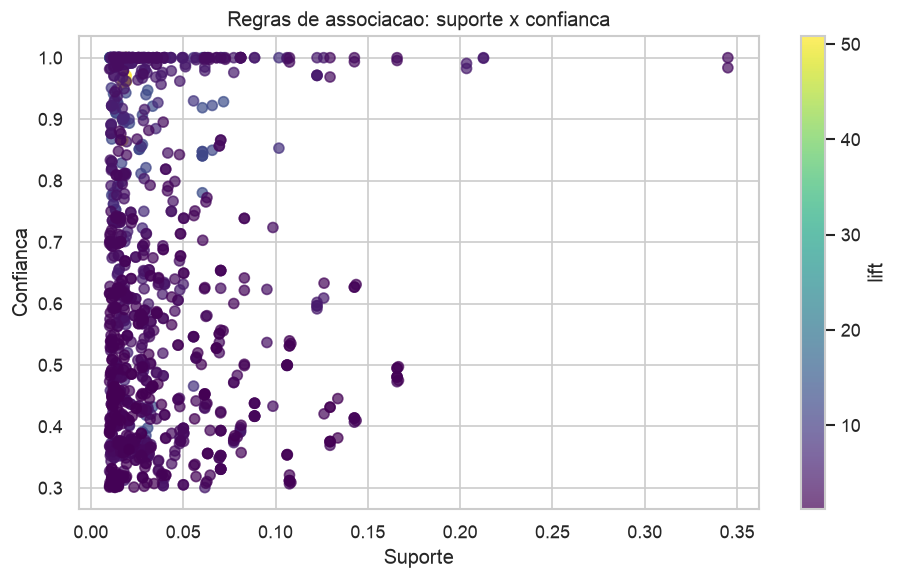

In [18]:
try:
    from mlxtend.frequent_patterns import apriori, association_rules
    MLXTEND_OK = True
except ImportError:
    MLXTEND_OK = False
    print("mlxtend nao instalado. Execute: pip install mlxtend")

if MLXTEND_OK:
    MIN_SUPORTE = CFG["analise"]["min_suporte"]
    MIN_CONFIANCA = CFG["analise"]["min_confianca"]
    MIN_LIFT = CFG["analise"]["min_lift"]
    TOP_N = CFG["analise"]["top_n_regras"]

    CATEGORICAS = ["Model Name", "Test Line", "Test Group",
                   "Test Station", "Reason Desc", "component_tipo"]

    df_regras = base_limpa[CATEGORICAS].copy()
    for col in CATEGORICAS:
        s = df_regras[col].fillna("SEM_VALOR").astype(str)
        vc = s.value_counts()
        raras = vc[vc < 10].index
        s = s.where(~s.isin(raras), "OUTROS")
        vc2 = s.value_counts()
        if len(vc2) > 15:
            manter = vc2.head(14).index
            s = s.where(s.isin(manter), "OUTROS")
        df_regras[col] = s

    onehot = pd.get_dummies(df_regras, dtype=bool)
    itemsets = apriori(onehot, min_support=MIN_SUPORTE, use_colnames=True, max_len=3)

    if len(itemsets) == 0:
        print("Nenhum itemset encontrado com o suporte minimo.")
    else:
        regras = association_rules(itemsets, metric="confidence", min_threshold=MIN_CONFIANCA)
        regras = regras[regras["lift"] > MIN_LIFT].sort_values("lift", ascending=False)

        if len(regras) == 0:
            print("Nenhuma regra encontrada com os limiares definidos.")
        else:
            regras["antecedentes"] = regras["antecedents"].apply(lambda x: ", ".join(sorted(x)))
            regras["consequentes"] = regras["consequents"].apply(lambda x: ", ".join(sorted(x)))
            saida = regras[["antecedentes", "consequentes", "support", "confidence", "lift"]].head(TOP_N)
            saida.columns = ["antecedentes", "consequentes", "suporte", "confianca", "lift"]
            print(f"{len(regras)} regras encontradas. Top {TOP_N}:")
            print(saida.to_string(index=False))

            fig, ax = plt.subplots(figsize=(8, 5))
            disp = ax.scatter(regras["support"], regras["confidence"],
                              c=regras["lift"], cmap="viridis", alpha=0.7)
            plt.colorbar(disp, label="lift")
            ax.set_title("Regras de associacao: suporte x confianca")
            ax.set_xlabel("Suporte")
            ax.set_ylabel("Confianca")
            plt.tight_layout()
            plt.show()

## 9. Detector de desvios de processo

Um desvio de processo é uma combinação de fatores — linha, estação, modelo ou
tipo de componente — cuja taxa de refalha é estatisticamente diferente da taxa
global. Identificar esses desvios é o núcleo da análise de causa-raiz: se a
refalha se distribui uniformemente, o problema é sistêmico; se se concentra em
pontos específicos, o problema é localizado e investigável.

O detector usa o **intervalo de confiança de Wilson**, adequado para proporções
com amostras pequenas — ao contrário do intervalo normal, ele não produz limites
negativos nem acima de 1. Um grupo é classificado como:

- **Desvio positivo** — limite inferior do IC acima da taxa global. A taxa de
  refalha é anormalmente alta.
- **Desvio negativo** — limite superior do IC abaixo da taxa global. A taxa é
  anormalmente baixa.
- **Normal** — o IC contém a taxa global.

O critério de amostra mínima é n ≥ 30, para evitar que grupos pequenos gerem
desvios espúrios.

Taxa global de refalha: 6.61% (346 de 5235)

--- Test Line (6 grupos com n >= 30) ---
    FT                                       n=1075  taxa= 13.9%  IC=[11.9%, 16.1%]
    A31_CELLA                                n= 373  taxa=  9.9%  IC=[7.3%, 13.4%]

--- Test Station (10 grupos com n >= 30) ---
    PCBA_VI0                                 n=  30  taxa= 23.3%  IC=[11.8%, 40.9%]
    FT0                                      n= 660  taxa= 22.1%  IC=[19.1%, 25.4%]
    ATET0                                    n=  75  taxa= 21.3%  IC=[13.6%, 31.9%]
    AOIB0                                    n=  30  taxa= 20.0%  IC=[9.5%, 37.3%]
    VI0                                      n= 376  taxa= 10.1%  IC=[7.5%, 13.6%]
    ATET1                                    n= 533  taxa=  9.9%  IC=[7.7%, 12.8%]

--- Linha + Estacao (15 grupos com n >= 30) ---
    FT | FT0                                 n= 641  taxa= 22.0%  IC=[19.0%, 25.4%]
    SMTB | ATET1                             n=  96  taxa= 19.8%  I

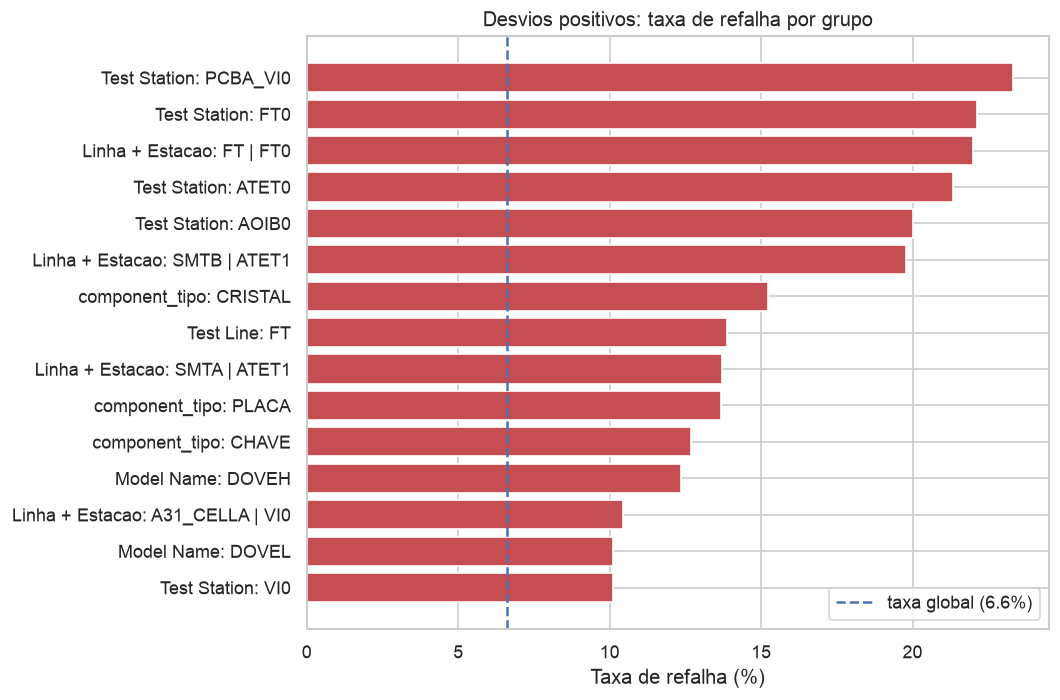

In [19]:
def wilson_interval(sucessos, n, z=1.96):
    """Intervalo de confianca de Wilson para uma proporcao."""
    if n == 0:
        return (0.0, 0.0)
    p = sucessos / n
    denom = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denom
    margem = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, centro - margem), min(1.0, centro + margem))


base_limpa["refalha"] = (base_limpa["estagio_defeito"] == 3).astype(int)
taxa_global = base_limpa["refalha"].mean()
print(f"Taxa global de refalha: {taxa_global*100:.2f}% "
      f"({base_limpa['refalha'].sum()} de {len(base_limpa)})\n")

AGRUPAMENTOS = {
    "Test Line": ["Test Line"],
    "Test Station": ["Test Station"],
    "Linha + Estacao": ["Test Line", "Test Station"],
    "Model Name": ["Model Name"],
    "component_tipo": ["component_tipo"],
}

todos = []
for nome, cols in AGRUPAMENTOS.items():
    grupo = base_limpa.groupby(cols).agg(
        n=("refalha", "size"),
        sucessos=("refalha", "sum"),
    ).reset_index()
    grupo = grupo[grupo["n"] >= 30].copy()
    if len(grupo) == 0:
        continue
    grupo["taxa"] = grupo["sucessos"] / grupo["n"]
    grupo["ic_inf"] = grupo.apply(lambda r: wilson_interval(r["sucessos"], r["n"])[0], axis=1)
    grupo["ic_sup"] = grupo.apply(lambda r: wilson_interval(r["sucessos"], r["n"])[1], axis=1)

    def classificar(r):
        if r["ic_inf"] > taxa_global:
            return "POSITIVO"
        if r["ic_sup"] < taxa_global:
            return "NEGATIVO"
        return "NORMAL"

    grupo["desvio"] = grupo.apply(classificar, axis=1)
    grupo["agrupamento"] = nome
    grupo["grupo"] = grupo[cols].astype(str).agg(" | ".join, axis=1)

    positivos = grupo[grupo["desvio"] == "POSITIVO"].sort_values("taxa", ascending=False)
    print(f"--- {nome} ({len(grupo)} grupos com n >= 30) ---")
    if len(positivos):
        for _, r in positivos.iterrows():
            print(f"    {r['grupo'][:40]:40s} n={r['n']:>4}  taxa={r['taxa']*100:>5.1f}%  "
                  f"IC=[{r['ic_inf']*100:.1f}%, {r['ic_sup']*100:.1f}%]")
    else:
        print("    Nenhum desvio positivo.")
    print()

    todos.append(grupo[["agrupamento", "grupo", "n", "taxa", "ic_inf", "ic_sup", "desvio"]])

df_desvios = pd.concat(todos, ignore_index=True).sort_values("taxa", ascending=False)

positivos = df_desvios[df_desvios["desvio"] == "POSITIVO"].head(15)
if len(positivos):
    fig, ax = plt.subplots(figsize=(9, 6))
    rotulos = positivos["agrupamento"] + ": " + positivos["grupo"]
    ax.barh(rotulos[::-1], positivos["taxa"][::-1] * 100, color="#C44E52")
    ax.axvline(taxa_global * 100, color="#4C72B0", linestyle="--",
               label=f"taxa global ({taxa_global*100:.1f}%)")
    ax.set_title("Desvios positivos: taxa de refalha por grupo")
    ax.set_xlabel("Taxa de refalha (%)")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 10. Síntese

### O que este notebook produziu

O pipeline de preparação foi executado do zero e produziu as bases analíticas
com os números validados contra o Apêndice A:

| Etapa | Linhas | Colunas |
|---|---|---|
| Corpus original | 5.526 | 63 |
| Após anonimização | 5.526 | 55 |
| Após limpeza | 5.235 | 25 |
| `base_defeito` | 5.235 | 103 |
| `base_evento` | 5.078 | 105 |

### Os três achados principais

**Primeiro:** o estágio do defeito está associado ao modo de falha
(`Reason Desc`, V = 0,3393) e à estação de teste (`Test Station`, V = 0,3195),
ambos com efeito moderado — mas não ao modelo do produto (`Model Name`,
V = 0,0939, desprezível).

**Segundo:** a estação **FT0** concentra taxa de refalha de 22,1% contra 6,61%
global — mais de três vezes, com n = 660 e intervalo de confiança que não cruza
a taxa global. A combinação FT / FT0 confirma o padrão (22,0%, n = 641),
indicando que o desvio está na estação, não na linha.

**Terceiro:** o processo de solda responde pela maior parte dos defeitos —
`COMPONENT SHIFT` (20,25%) e `NON-WETTING` (12,89%) somam 33,1% das causas
declaradas.

### Limitações

- Associação não é causalidade. O V de Cramér e o lift indicam onde investigar,
  não a causa do defeito.
- O desequilíbrio de 93,4% / 6,6% entre primeira falha e refalha limita a
  potência de comparações entre os grupos.
- As regras de associação de maior lift são estruturais (hierarquia
  estação → grupo → linha), não causais.
- A confirmação causal exige inspeção do processo físico.